# CASP: Run protein structure prediction

## Input protein sequence(s)

In [ ]:
#@title Input protein sequence(s), then hit `Runtime` -> `Run all`
import os
from datetime import datetime
import re
import hashlib
import random
import subprocess

import ipywidgets as widgets
from IPython.display import display

from sys import version_info
python_version = f"{version_info.major}.{version_info.minor}"

NOW = datetime.now().strftime("%Y%m%d-%H%M%S-%f")

query_sequence = widgets.Textarea(
    value=">test\nPIAQIHILEGRSDEQKETLIREVSEAISRSLDAPLTSVRVIITEMAKGHFGIGGELASK\n",
    placeholder='Fasta format sequence file',
    description='query_sequence:',
    layout=widgets.Layout(width="100%", rows="8"),
)
label = widgets.Text(
    value=f"{NOW}",
    placeholder="Job Id, default=`date +%Y%m%d-%H%M%S-%N`",
    description="label:",
)
model_preset = widgets.Dropdown(
    options=["monomer", "monomer_casp14", "monomer_ptm", "multimer"],
    value="monomer_ptm",
    description='model_preset:',
    disabled=False,
)
num_predictions_per_model = widgets.IntSlider(
    value=0,
    min=0,
    max=100,
    step=1,
    description="num_predictions_per_model:",
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='d',
)
num_predictions_per_model_label = widgets.Label(
    value="Note: 0 for AlphaFold2's default value",
    label_style="warning",
)
with subprocess.Popen("nvidia-smi --list-gpus", text=True, shell=True, stdout=subprocess.PIPE) as p:
  gpu_list, e = p.communicate()
if not e:
  gpu_devices = widgets.Dropdown(
      options=[(gpu, i) for i, gpu in enumerate(gpu_list.splitlines())],
      value=0,
      description="gpu_devices:",
      disabled=False,
  )
else:
  gpu_devices = widges.Text(
    value="all",
    description="gpu_devices:",
    disabled=True,
  )

display(query_sequence, label, model_preset, num_predictions_per_model, num_predictions_per_model_label, gpu_devices)

## Run AlphaFold2

In [ ]:
from Bio import SeqIO

PWD = os.path.dirname(globals()['_dh'][0])
timestamp = label.value.strip()
data_path = os.path.join(PWD, "data", timestamp)
seq_file = os.path.join(data_path, "seq.fasta")

os.makedirs(data_path, exist_ok=True)
with open(seq_file, "w") as f:
  f.write(query_sequence.value)

seqs = list(SeqIO.parse(seq_file, "fasta"))
if len(seqs) > 1:
  assert model_preset.value == "multimer"

signal_file = os.path.join(data_path, "DONE")
if not os.path.exists(signal_file):
  cmd = os.path.join(PWD, "run_casp.sh")
  model_params = f"--model_preset={model_preset.value} --use_precomputed_msas"
  if num_predictions_per_model.value > 0:
    if model_preset.value == "multimer":
      model_params = f"{model_params} --num_multimer_predictions_per_model={num_predictions_per_model.value}"
    else:
      model_params = f"{model_params} --num_predictions_per_model={num_predictions_per_model.value}"
  cmd = f"bash -x {cmd} -t {timestamp} -p \"{model_params}\" --gpu_devices={gpu_devices.value} {seq_file}"
  print(f"Run {cmd}")
  r = subprocess.run(cmd, shell=True)
  if r.returncode == 0:
    os.system(f"touch {signal_file}")
else:
  print(f"Job:{timestamp} DONE.")

Run bash -x /mnt/data/yuchungong/CASP/run_casp.sh -t 20240319-050910-226947 -p "--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20" --gpu_devices=0 /mnt/data/yuchungong/CASP/data/20240319-050910-226947/seq.fasta
ARGS: -t 20240319-050910-226947 -p --model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20 --gpu_devices 0 -- /mnt/data/yuchungong/CASP/data/20240319-050910-226947/seq.fasta
1:-t
2:20240319-050910-226947
1:-p
2:--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20
1:--gpu_devices
2:0
1:--
2:/mnt/data/yuchungong/CASP/data/20240319-050910-226947/seq.fasta
timestamp: 20240319-050910-226947
enable_domain_split: 0


++ readlink -f /mnt/data/yuchungong/CASP/run_casp.sh
+ CWD=/mnt/data/yuchungong/CASP/run_casp.sh
++ dirname /mnt/data/yuchungong/CASP/run_casp.sh
+ CWD=/mnt/data/yuchungong/CASP
+ cd /mnt/data/yuchungong/CASP
+ msa_tool_home=/public/dbu
+ msa_tool_srv=dbu@idnode17
++ date +%Y%m%d-%H%M%S-%N
+ timestamp=20240319-051014-746749809
+ output_dir=/mnt/data/yuchungong/CASP/data
+ model_params=
+ gpu_devices=all
+ enable_domain_split=0
+ enable_deep_msa2=0
++ getopt --options t:o:p:g:sh --longoptions timestamp:,output_dir:,model_params:,gpu_devices:,msa_tool_home:,msa_tool_srv:,enable_domain_split,enable_deep_msa2,help -- -t 20240319-050910-226947 -p '--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20' --gpu_devices=0 /mnt/data/yuchungong/CASP/data/20240319-050910-226947/seq.fasta
+ ARGS=' -t '\''20240319-050910-226947'\'' -p '\''--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20'\'' --gpu_devices '\''0'\'' -- '\''/mnt/data/yuchungong/

sending incremental file list
seq.fasta
            458 100%    0.00kB/s    0:00:00 (xfr#1, to-chk=0/1)

sent 577 bytes  received 35 bytes  408.00 bytes/sec
total size is 458  speedup is 0.75
start run msa_tool


+ msa_tool_file_list=
+ for f in $*
++ basename /mnt/data/yuchungong/CASP/data/20240319-050910-226947/seq.fasta
+ f=seq.fasta
+ msa_tool_file_list=' /public/dbu/CASP/data/20240319-050910-226947/fasta/seq.fasta'
+ af2_pred_data_dir=/mnt/data/yuchungong/CASP/data/20240319-050910-226947
+ mkdir -p /mnt/data/yuchungong/CASP/data/20240319-050910-226947
+ '[' 0 -eq 1 ']'
+ echo 'start run msa_tool'
+ msa_params=
+ '[' 'x--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20' '!=' x ']'
+ msa_params='-p "--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20"'
+ ssh dbu@idnode17 bash -x /public/dbu/CASP/run_msa_tool.sh -d /public/dbu/data/af2_db -o /public/dbu/CASP/data/20240319-050910-226947/msa '-p "--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20"' /public/dbu/CASP/data/20240319-050910-226947/fasta/seq.fasta
++ readlink -f /public/dbu/CASP/run_msa_tool.sh
+ CWD=/public/dbu/CASP/run_msa_tool.sh
++ dirname /p

msa_tool_run done
receiving incremental file list
fasta/
fasta/seq.fasta
            458 100%  447.27kB/s    0:00:00 (xfr#1, to-chk=0/2)

sent 47 bytes  received 596 bytes  257.20 bytes/sec
total size is 458  speedup is 0.71


+ rsync -avP -e ssh dbu@idnode17:/public/dbu/CASP/data/20240319-050910-226947/msa /mnt/data/yuchungong/CASP/data/20240319-050910-226947


receiving incremental file list
msa/
msa/seq/
msa/seq/features.pkl
     52,106,677 100%   19.08MB/s    0:00:02 (xfr#1, to-chk=5/8)
msa/seq/msas/
msa/seq/msas/bfd_uniref_hits.a3m
      1,892,593 100%    2.45MB/s    0:00:00 (xfr#2, to-chk=3/8)
msa/seq/msas/mgnify_hits.sto
      1,498,924 100%    1.64MB/s    0:00:00 (xfr#3, to-chk=2/8)
msa/seq/msas/pdb_hits.hhr
        834,364 100%  833.99kB/s    0:00:00 (xfr#4, to-chk=1/8)
msa/seq/msas/uniref90_hits.sto
     29,471,453 100%   10.23MB/s    0:00:02 (xfr#5, to-chk=0/8)

sent 139 bytes  received 85,825,396 bytes  10,097,121.76 bytes/sec
total size is 85,804,011  speedup is 1.00
Start predict (/mnt/data/yuchungong/CASP/data/20240319-050910-226947/fasta/seq.fasta|1) Tue Mar 19 11:28:27 UTC 2024


+ af2_pred_file_list=
+ for f in $*
++ basename /mnt/data/yuchungong/CASP/data/20240319-050910-226947/seq.fasta
+ f=seq.fasta
+ af2_pred_file_list=' /mnt/data/yuchungong/CASP/data/20240319-050910-226947/fasta/seq.fasta'
+ '[' 0 -eq 1 ']'
+ '[' 'x--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20' == x ']'
++ echo --model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20
++ grep use_precomputed_msas
++ wc -l
+ has_use_precomputed_msas=1
+ '[' 1 -eq 0 ']'
+ model_params='--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20 --gpu_devices=0'
+ bash -x run_alphafold.sh -m alphafold -d db -o /mnt/data/yuchungong/CASP/data/20240319-050910-226947/msa -p '--model_preset=monomer_ptm --use_precomputed_msas --num_predictions_per_model=20 --gpu_devices=0' /mnt/data/yuchungong/CASP/data/20240319-050910-226947/fasta/seq.fasta
++ readlink -f run_alphafold.sh
+ CWD=/mnt/data/yuchungong/CASP/run_alphafold.sh
++ dirname /mnt

## Plots




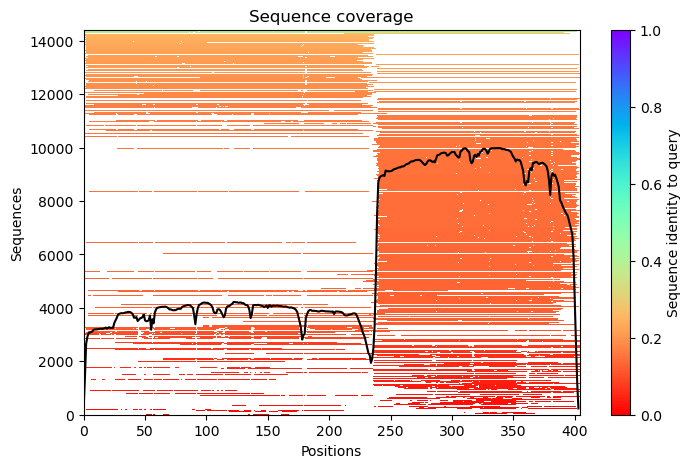
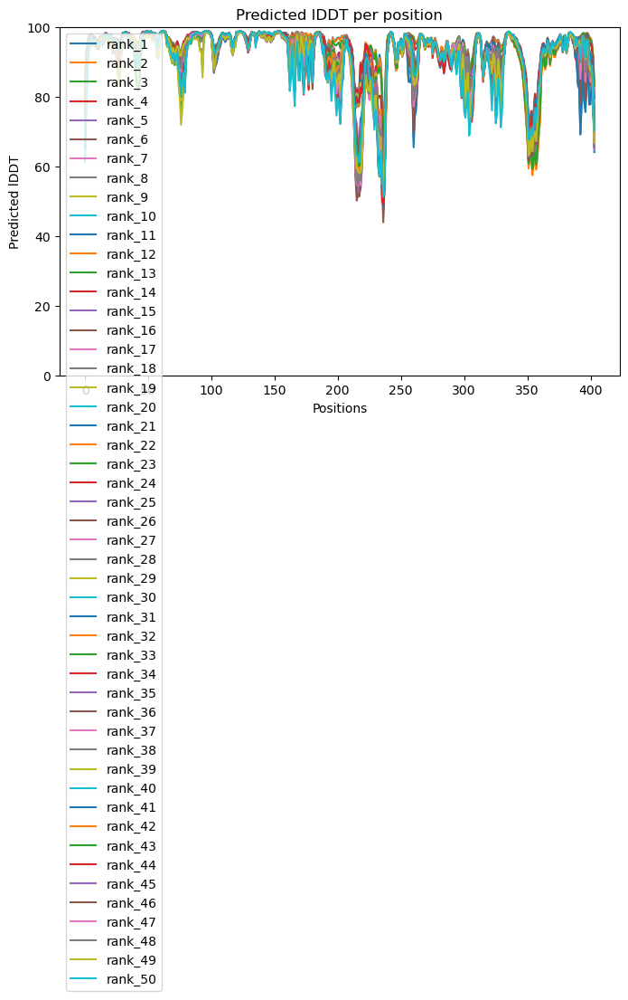

[('model_3_ptm_pred_0', 95.00646352200589), ('model_3_ptm_pred_6', 94.87916366498514), ('model_3_ptm_pred_1', 94.30345867782059), ('model_3_ptm_pred_3', 93.80386161662264), ('model_5_ptm_pred_3', 93.46313220401748), ('model_3_ptm_pred_4', 93.43660283400122), ('model_4_ptm_pred_0', 93.14740547511312), ('model_3_ptm_pred_2', 93.0447842624809), ('model_4_ptm_pred_6', 92.98223661731497), ('model_3_ptm_pred_9', 92.96043395006697), ('model_5_ptm_pred_9', 92.95248909984535), ('model_5_ptm_pred_2', 92.83580271383352), ('model_5_ptm_pred_5', 92.7418476200483), ('model_4_ptm_pred_1', 92.74175050565236), ('model_5_ptm_pred_1', 92.58611163008344), ('model_4_ptm_pred_4', 92.55148273188655), ('model_1_ptm_pred_4', 92.50851680338074), ('model_3_ptm_pred_7', 92.4856984828258), ('model_1_ptm_pred_5', 92.47495224276804), ('model_4_ptm_pred_5', 92.47306946504737), ('model_5_ptm_pred_6', 92.34072719469664), ('model_3_ptm_pred_8', 92.31831788043323), ('model_5_ptm_pred_8', 92.30196332509254), ('model_3_ptm

In [15]:
import os
os.environ["PYTHONPATH"] = PWD
os.chdir(PWD)

import base64
import json
from html import escape
import pickle

import numpy as np

from IPython.display import display, HTML

from contrib.plot import plot_msa_v2, plot_paes, plot_plddts


timestamp = label.value.strip()
data_path = os.path.join(PWD, "data", timestamp)
result_path = os.path.join(data_path, "msa", "seq")

# plot MSAs
feature_dict_file = os.path.join(result_path, "features.pkl")
with open(feature_dict_file, "rb") as f:
  feature_dict = pickle.load(f)

# see: https://stackoverflow.com/a/53688522
def image_to_data_url(filename):
  ext = filename.split('.')[-1]
  prefix = f'data:image/{ext};base64,'
  with open(filename, 'rb') as f:
    img = f.read()
  return prefix + base64.b64encode(img).decode('utf-8')

def plot_png(plot_obj, png_name):
  png_file = os.path.join(result_path, png_name)
  plot_obj.savefig(png_file, bbox_inches='tight')
  plot_obj.close()

  return image_to_data_url(png_file)

msa_png = plot_png(plot_msa_v2(feature_dict), "msa.png")


# load ranking scores
ranking_debug_file = os.path.join(result_path, "ranking_debug.json")
with open(ranking_debug_file, "r") as f:
  rankings = json.loads(f.read())
rankings = [(model_name, rankings["plddts"][model_name]) for model_name in rankings["order"]]

# load metrics
plddts, paes = [], []
for n, (model_name, plddt) in enumerate(rankings):
  model_result_file = os.path.join(result_path, f"result_{model_name}.pkl")
  with open(model_result_file, "rb") as f:
    model_result = pickle.load(f)
  plddt_result_file = os.path.join(result_path, f"confidence_{model_name}.json")
  with open(plddt_result_file, "r") as f:
    plddt = json.loads(f.read())
  plddts.append(plddt)
  pae_result_file = os.path.join(result_path, f"pae_{model_name}.json")
  if os.path.exists(pae_result_file):
    with open(pae_result_file, "r") as f:
      pae = json.loads(f.read())
    paes.append(pae)

# show PDBs

# make pLDDT plot
plddt_png = plot_png(plot_plddts([np.asarray(x["confidenceScore"]) for x in plddts]), "plddt.png")
# make PAE plot
if paes:
  pae_png = plot_png(plot_paes([np.asarray(pae[0]["predicted_aligned_error"]) for pae in paes]), "paes.png")
else:
  pae_png = ""

display(HTML(f"""
<style>
  img {{
    float:left;
  }}
  .full {{
    max-width:100%;
  }}
  .half {{
    max-width:50%;
  }}
  @media (max-width:640px) {{
    .half {{
      max-width:100%;
    }}
  }}
</style>
<div style="max-width:90%; padding:2em;">
  <h1>Plots for {escape(timestamp)}</h1>
  { '<!--' if pae_png == '' else '' }<img src="{pae_png}" class="full" />{ '-->' if pae_png == '' else '' }
  <img src="{msa_png}" class="half" />
  <img src="{plddt_png}" class="half" />
</div>
"""))
print(rankings)



## Display 3D structure

In [8]:

color = widgets.Dropdown(
    options=["pLDDT", "rainbow"],
    value="pLDDT",
    description='color:',
    disabled=False,
)

display(color)

Dropdown(description='color:', options=('pLDDT', 'rainbow'), value='pLDDT')

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

... (40 outputs left out)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

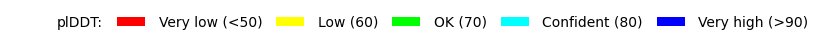

In [14]:
import py3Dmol
import glob
import matplotlib.pyplot as plt
from contrib.plot import plot_plddt_legend
from contrib.plot import pymol_color_list, alphabet_list

# rank_num = rank_num.value #@param ["1", "2", "3", "4", "5"] {type:"raw"}
# color = color.value #@param ["chain", "lDDT", "rainbow"]
show_sidechains = False #@param {type:"boolean"}
show_mainchains = False #@param {type:"boolean"}

def show_pdb(rank_num, pdb_file, show_sidechains=False, show_mainchains=False, color="lDDT"):
  model_name = f"rank_{rank_num}"
  view = py3Dmol.view(js='https://3dmol.org/build/3Dmol.js',)
  view.addModel(open(pdb_file,'r').read(), 'pdb')

  if color == "pLDDT":
    view.setStyle({'cartoon': {'colorscheme': {'prop':'b','gradient': 'roygb','min':50,'max':90}}})
  elif color == "rainbow":
    view.setStyle({'cartoon': {'color':'spectrum'}})
  elif color == "chain":
    chains = len(queries[0][1]) + 1 if is_complex else 1
    for n,chain,color in zip(range(chains),alphabet_list,pymol_color_list):
       view.setStyle({'chain':chain},{'cartoon': {'color':color}})

  if show_sidechains:
    BB = ['C','O','N']
    view.addStyle({'and':[{'resn':["GLY","PRO"],'invert':True},{'atom':BB,'invert':True}]},
                        {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"GLY"},{'atom':'CA'}]},
                        {'sphere':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"PRO"},{'atom':['C','O'],'invert':True}]},
                        {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
  if show_mainchains:
    BB = ['C','O','N','CA']
    view.addStyle({'atom':BB},{'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})

  view.zoomTo()
  return view


# tag, _ = rankings[rank_num.value]
for i, (model_name, _) in enumerate(rankings):
  pdb_file = os.path.join(result_path, f"unrelaxed_{model_name}.pdb")
  show_pdb(i + 1, pdb_file, show_sidechains, show_mainchains, color.value).show()
if color.value == "pLDDT":
  plot_plddt_legend().show()